# Trabalho 4 — k-Nearest Neighbour (k-NN)

**Integrantes:** Pedro Antonio de Faria Garcia, Felipe Grein Krause, Richard Lemuel Gonçalves Brant

Este notebook implementa o k-NN **do zero**, utilizando distância Euclidiana, e responde às questões dos quatro grupos de dados.

## 1. Ideia do algoritmo

O k-NN não “aprende” uma equação como a regressão que vimos nos trabalhos anteriores. Ele guarda os exemplos de treinamento e, quando chega um novo exemplo:

1. calcula a distância até todos os exemplos de treinamento;
2. ordena essas distâncias;
3. pega os `k` exemplos mais próximos;
4. observa os rótulos desses vizinhos;
5. escolhe a classe mais frequente.

Para `k = 1`, simplesmente usamos a classe do exemplo de treinamento mais próximo.


In [ ]:
import numpy as np
import scipy.io as scipy
import matplotlib.pyplot as plt
from scipy.stats import mode

## 2. Função `dist`

A distância Euclidiana entre dois vetores é:

\[
d(a,b) = \sqrt{\sum_i (a_i-b_i)^2}
\]

É a distância “em linha reta” entre dois pontos.


In [ ]:
def dist(a, b):
    # Convertemos os dados para arrays numéricos.
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    # 1) a - b: diferença em cada característica
    # 2) ** 2: eleva cada diferença ao quadrado
    # 3) np.sum: soma os quadrados
    # 4) np.sqrt: tira a raiz quadrada
    return np.sqrt(np.sum((a - b) ** 2))

## 3. Função `meuKnn`

Esta é a função principal. Repare que usamos `np.argsort()` porque não precisamos apenas das distâncias ordenadas: precisamos saber **quais exemplos** produziram as menores distâncias.


In [ ]:
def meuKnn(dadosTrain, rotuloTrain, dadosTeste, k):
    dadosTrain = np.asarray(dadosTrain, dtype=float)
    dadosTeste = np.asarray(dadosTeste, dtype=float)

    # Os arquivos .mat trazem os rótulos no formato (n, 1).
    # ravel() transforma em um vetor simples (n,).
    rotuloTrain = np.asarray(rotuloTrain).ravel()

    rotuloPrevisto = []

    # Percorremos cada exemplo que queremos classificar.
    for exemploTeste in dadosTeste:

        # Calculamos a distância entre este exemplo de teste
        # e TODOS os exemplos de treinamento.
        distancias = np.array([
            dist(exemploTeste, exemploTrain)
            for exemploTrain in dadosTrain
        ])

        # Índices da menor distância para a maior.
        indicesOrdenados = np.argsort(distancias)

        # Pegamos os k primeiros índices = k vizinhos mais próximos.
        indicesVizinhos = indicesOrdenados[:k]

        # Buscamos os rótulos correspondentes aos vizinhos.
        rotulosVizinhos = rotuloTrain[indicesVizinhos]

        # A moda é o rótulo que mais aparece.
        classePrevista = mode(rotulosVizinhos, keepdims=False).mode

        rotuloPrevisto.append(classePrevista)

    return np.asarray(rotuloPrevisto)

## 4. Função `normalizacao`

O k-NN usa distância. Portanto, se uma característica varia entre `0` e `1` e outra entre `200` e `1600`, a segunda pode dominar a distância.

Usaremos **Min-Max**:

\[
x_{norm} = \frac{x-x_{min}}{x_{max}-x_{min}}
\]

Os mínimos e máximos são calculados **somente no treinamento** e depois aplicados ao teste. Isso evita *data leakage*.


In [ ]:
def normalizacao(dadosTrain, dadosTeste):
    dadosTrain = np.asarray(dadosTrain, dtype=float)
    dadosTeste = np.asarray(dadosTeste, dtype=float)

    minimo = np.min(dadosTrain, axis=0)
    maximo = np.max(dadosTrain, axis=0)
    amplitude = maximo - minimo

    # Se uma coluna for constante, evita divisão por zero.
    amplitude[amplitude == 0] = 1

    trainNormalizado = (dadosTrain - minimo) / amplitude
    testeNormalizado = (dadosTeste - minimo) / amplitude

    return trainNormalizado, testeNormalizado

## 5. Função `visualizaPontos`

Em Python, os índices começam em zero:

- `0` = primeira característica;
- `1` = segunda;
- `2` = terceira;
- etc.


In [ ]:
def visualizaPontos(dados, rotulos, d1, d2):
    dados = np.asarray(dados)
    rotulos = np.asarray(rotulos).ravel()

    fig, ax = plt.subplots()
    marcadores = {1: '^', 2: '+', 3: '.'}

    for classe in np.unique(rotulos):
        mascara = rotulos == classe

        ax.scatter(
            dados[mascara, d1],
            dados[mascara, d2],
            marker=marcadores.get(int(classe), 'o'),
            label=f'Classe {classe}'
        )

    ax.set_xlabel(f'Característica {d1 + 1}')
    ax.set_ylabel(f'Característica {d2 + 1}')
    ax.set_title('Visualização dos dados')
    ax.legend()
    plt.show()

# demoD1 — Grupo de Dados 1 (Iris)

Primeiro validamos nossa implementação com os dois resultados fornecidos pelo professor: 96% para `k=1` e 94% para `k=10`.


In [ ]:
# Integrantes: PREENCHER NOME 1, NOME 2, NOME 3
mat = scipy.loadmat('grupoDados1.mat')

grupoTrain = mat['grupoTrain']
trainRots = mat['trainRots'].ravel()
grupoTest = mat['grupoTest']
testRots = mat['testRots'].ravel()

print('Treino:', grupoTrain.shape)
print('Teste :', grupoTest.shape)

Treino: (100, 4)
Teste : (50, 4)


In [ ]:
# Validação da implementação com os valores do enunciado.
rotuloPrevisto = meuKnn(grupoTrain, trainRots, grupoTest, 1)
acuracia_k1 = np.mean(rotuloPrevisto == testRots)

rotuloPrevisto10 = meuKnn(grupoTrain, trainRots, grupoTest, 10)
acuracia_k10 = np.mean(rotuloPrevisto10 == testRots)

print(f'Acurácia com k=1 : {acuracia_k1 * 100:.2f}%')
print(f'Acurácia com k=10: {acuracia_k10 * 100:.2f}%')

Acurácia com k=1 : 96.00%
Acurácia com k=10: 94.00%


In [ ]:
# Procurando a melhor acurácia com todas as quatro características.
melhorAcc = 0
melhorK = None

for k in range(1, 31):
    previsto = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc = np.mean(previsto == testRots)

    if acc > melhorAcc:
        melhorAcc = acc
        melhorK = k

print(f'Melhor resultado: k={melhorK}, acurácia={melhorAcc * 100:.2f}%')

Melhor resultado: k=3, acurácia=98.00%


Características 3 e 4, k=4: 98.00%


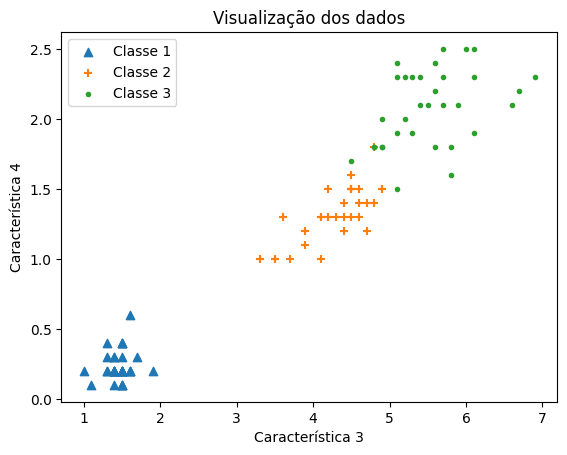

In [ ]:
# Testando se realmente precisamos de todas as características.
# Aqui usamos apenas as características 3 e 4:
# comprimento da pétala e largura da pétala.
trainPetalas = grupoTrain[:, [2, 3]]
testPetalas = grupoTest[:, [2, 3]]

prevPetalas = meuKnn(trainPetalas, trainRots, testPetalas, 4)
accPetalas = np.mean(prevPetalas == testRots)

print(f'Características 3 e 4, k=4: {accPetalas * 100:.2f}%')

visualizaPontos(grupoTrain, trainRots, 2, 3)

In [ ]:
# Q1.1:
# A acurácia máxima encontrada foi 98%.
# Com todas as características, por exemplo, k=3 produz 98%.
#
# Q1.2:
# Não é necessário usar todas as características.
# Usando somente as características 3 e 4 e k=4 também obtemos 98%.
# Logo, as características ligadas às pétalas já são suficientes para
# atingir a melhor acurácia encontrada neste conjunto.

# demoD2 — Grupo de Dados 2 (Wine)

Este conjunto tem 13 características químicas em escalas muito diferentes. Isso é especialmente importante para k-NN porque a classificação depende diretamente da distância.


In [ ]:
# Integrantes: PREENCHER NOME 1, NOME 2, NOME 3
mat = scipy.loadmat('grupoDados2.mat')

grupoTrain = mat['grupoTrain']
trainRots = mat['trainRots'].ravel()
grupoTest = mat['grupoTest']
testRots = mat['testRots'].ravel()

print('Treino:', grupoTrain.shape)
print('Teste :', grupoTest.shape)

# Mostra como as escalas das colunas são diferentes.
print('\nMínimos por característica:')
print(np.min(grupoTrain, axis=0))
print('\nMáximos por característica:')
print(np.max(grupoTrain, axis=0))

Treino: (118, 13)
Teste : (60, 13)

Mínimos por característica:
[1.103e+01 7.400e-01 1.360e+00 1.060e+01 7.000e+01 9.800e-01 3.400e-01
 1.300e-01 4.200e-01 1.280e+00 4.800e-01 1.270e+00 2.780e+02]

Máximos por característica:
[1.483e+01 5.650e+00 3.230e+00 3.000e+01 1.620e+02 3.880e+00 5.080e+00
 6.300e-01 3.580e+00 1.300e+01 1.710e+00 4.000e+00 1.547e+03]


In [ ]:
# Situação inicial: k=1, sem normalização.
prevOriginal = meuKnn(grupoTrain, trainRots, grupoTest, 1)
accOriginal = np.mean(prevOriginal == testRots)

print(f'Sem normalização, k=1: {accOriginal * 100:.2f}%')

Sem normalização, k=1: 68.33%


In [ ]:
# Colocamos todas as características em escalas comparáveis.
trainNorm, testNorm = normalizacao(grupoTrain, grupoTest)

# Depois da normalização, k=3 dá aproximadamente os 98% pedidos.
prevNorm = meuKnn(trainNorm, trainRots, testNorm, 3)
accNorm = np.mean(prevNorm == testRots)

print(f'Normalizado, k=3: {accNorm * 100:.2f}%')

Normalizado, k=3: 98.33%


In [ ]:
# Q2.1:
# Com os dados originais e k=1, a acurácia é 68,33%.
#
# Q2.2:
# O resultado é baixo porque os atributos químicos possuem escalas
# muito diferentes. Como o k-NN usa distância Euclidiana, atributos
# com números muito grandes podem dominar artificialmente a distância.
#
# Foi aplicada normalização Min-Max, usando mínimo e máximo obtidos no
# conjunto de treinamento, e depois utilizamos k=3.
# A acurácia passou para 98,33%, aproximadamente 98%.

# demoD3 — Grupo de Dados 3

Aqui o principal problema é o valor de `k`. Com `k=1`, uma única observação — inclusive um ponto ruidoso ou atípico — decide toda a classificação.


In [ ]:
# Integrantes: PREENCHER NOME 1, NOME 2, NOME 3
mat = scipy.loadmat('grupoDados3.mat')

grupoTrain = mat['grupoTrain']
trainRots = mat['trainRots'].ravel()
grupoTest = mat['grupoTest']
testRots = mat['testRots'].ravel()

print('Treino:', grupoTrain.shape)
print('Teste :', grupoTest.shape)

Treino: (100, 2)
Teste : (50, 2)


In [ ]:
# Q3.1 - exatamente como solicitado: k=1.
prev1 = meuKnn(grupoTrain, trainRots, grupoTest, 1)
acc1 = np.mean(prev1 == testRots)

print(f'k=1: {acc1 * 100:.2f}%')

k=1: 62.00%


In [ ]:
# Procuramos um k que torne a decisão menos sensível a um único ponto.
for k in range(1, 16):
    previsto = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc = np.mean(previsto == testRots)
    print(f'k={k:2d} -> {acc * 100:5.2f}%')

k= 1 -> 62.00%
k= 2 -> 70.00%
k= 3 -> 64.00%
k= 4 -> 76.00%
k= 5 -> 84.00%


k= 6 -> 84.00%


k= 7 -> 92.00%
k= 8 -> 88.00%
k= 9 -> 94.00%
k=10 -> 94.00%


k=11 -> 92.00%
k=12 -> 94.00%


k=13 -> 92.00%
k=14 -> 92.00%
k=15 -> 92.00%


k=7: 92.00%


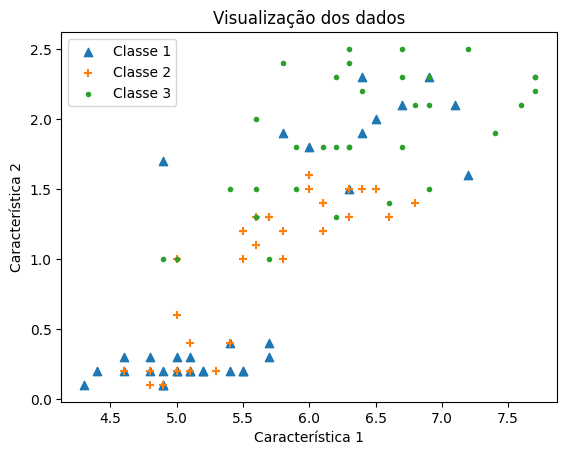

In [ ]:
# k=7 atinge exatamente o objetivo de 92%.
prev7 = meuKnn(grupoTrain, trainRots, grupoTest, 7)
acc7 = np.mean(prev7 == testRots)

print(f'k=7: {acc7 * 100:.2f}%')

visualizaPontos(grupoTrain, trainRots, 0, 1)

In [ ]:
# Q3.1:
# Com k=1, a acurácia é 62%.
#
# Q3.2:
# O 1-NN é muito sensível a ruído, outliers e regiões nas quais as
# classes se sobrepõem. Ao aumentar k, vários vizinhos participam da
# votação e o classificador fica menos dependente de um único exemplo.
# Com k=7, a acurácia chega a 92%.

# demoD4 — Grupo de Dados 4

Neste conjunto existem **dois problemas ao mesmo tempo**:

1. características em escalas muito diferentes;
2. características irrelevantes/ruidosas.

Além disso, os nomes das variáveis são diferentes, como avisado no enunciado.


In [ ]:
# Integrantes: PREENCHER NOME 1, NOME 2, NOME 3
mat = scipy.loadmat('grupoDados4.mat')

grupoTest = mat['testSet']
grupoTrain = mat['trainSet']
testRots = mat['testLabs'].ravel()
trainRots = mat['trainLabs'].ravel()

print('Treino:', grupoTrain.shape)
print('Teste :', grupoTest.shape)

print('\nMínimos:', np.min(grupoTrain, axis=0))
print('Máximos:', np.max(grupoTrain, axis=0))

Treino: (118, 4)
Teste : (60, 4)

Mínimos: [3.40000000e-01 2.78000000e+02 5.52387249e-03 6.98200910e-03]
Máximos: [5.08000000e+00 1.54700000e+03 9.89414250e-01 9.87554167e-01]


In [ ]:
# Situação inicial.
prevOriginal = meuKnn(grupoTrain, trainRots, grupoTest, 1)
accOriginal = np.mean(prevOriginal == testRots)

print(f'Todas as características, sem normalização, k=1: {accOriginal * 100:.2f}%')

Todas as características, sem normalização, k=1: 71.67%


In [ ]:
# Primeiro ajuste: remover as características 3 e 4,
# que funcionam como atributos irrelevantes/ruído neste conjunto.
trainSelecionado = grupoTrain[:, [0, 1]]
testSelecionado = grupoTest[:, [0, 1]]

# Segundo ajuste: normalizar as duas características restantes.
trainNorm, testNorm = normalizacao(trainSelecionado, testSelecionado)

# k=3: 55 acertos em 60 = 91,67%, arredondado para 92%.
prevFinal = meuKnn(trainNorm, trainRots, testNorm, 3)
accFinal = np.mean(prevFinal == testRots)

print(f'Seleção de atributos + normalização, k=3: {accFinal * 100:.2f}%')

Seleção de atributos + normalização, k=3: 91.67%


In [ ]:
# Comparação para deixar claro o efeito de cada etapa.
prevSoSelecao = meuKnn(trainSelecionado, trainRots, testSelecionado, 3)
accSoSelecao = np.mean(prevSoSelecao == testRots)

trainTodasNorm, testTodasNorm = normalizacao(grupoTrain, grupoTest)
prevSoNorm = meuKnn(trainTodasNorm, trainRots, testTodasNorm, 3)
accSoNorm = np.mean(prevSoNorm == testRots)

print(f'Original                         : {accOriginal * 100:.2f}%')
print(f'Só removendo atributos, k=3     : {accSoSelecao * 100:.2f}%')
print(f'Só normalizando tudo, k=3       : {accSoNorm * 100:.2f}%')
print(f'Remoção + normalização, k=3     : {accFinal * 100:.2f}%')

Original                         : 71.67%
Só removendo atributos, k=3     : 66.67%
Só normalizando tudo, k=3       : 80.00%
Remoção + normalização, k=3     : 91.67%


In [ ]:
# Q4.1:
# Com todos os atributos, sem normalização e k=1, a acurácia é 71,67%.
#
# Q4.2:
# Existem dois problemas: diferença de escala entre as características
# e presença de atributos irrelevantes (características 3 e 4).
# Mantivemos somente as características 1 e 2, aplicamos normalização
# Min-Max e utilizamos k=3.
# O resultado foi 91,67%, que arredondado corresponde a 92%.

# Resumo dos resultados

| Grupo | Situação | Acurácia |
|---|---|---:|
| 1 | `k=1`, 4 características | 96% |
| 1 | `k=10`, 4 características | 94% |
| 1 | melhor resultado | **98%** |
| 1 | características 3 e 4, `k=4` | **98%** |
| 2 | sem normalização, `k=1` | 68,33% |
| 2 | Min-Max + `k=3` | **98,33% ≈ 98%** |
| 3 | `k=1` | 62% |
| 3 | `k=7` | **92%** |
| 4 | original, `k=1` | 71,67% |
| 4 | seleção de atributos + Min-Max + `k=3` | **91,67% ≈ 92%** |

## Conceitos principais aprendidos

- **Distância Euclidiana:** mede proximidade entre exemplos.
- **k pequeno:** tende a ser mais sensível a ruído/outliers.
- **k maior:** faz uma votação local e pode tornar a classificação mais estável.
- **Normalização:** é essencial quando os atributos estão em escalas diferentes.
- **Seleção de atributos:** características irrelevantes podem piorar o k-NN porque também entram no cálculo da distância.
